# NLP Lab Assignment 10: Comparative Analysis of Word Embeddings (Word2Vec, GloVe, FastText) on Semantic Analogies & Neural Text Classification

**Course:** AI357 - Natural Language Processing  
**Institution:** Sardar Vallabhbhai National Institute of Technology (SVNIT), Surat  
**Department:** Department of Artificial Intelligence  
**Semester:** 5th Semester  

---

## Executive Abstract & Theoretical Framework

This assignment presents a rigorous comparative evaluation of three landmark distributed word representation models:
1. **Google Word2Vec (Mikolov et al., 2013):** Continuous Skip-Gram with Negative Sampling trained on Google News (~100B tokens, 300d).
2. **GloVe (Pennington et al., 2014):** Global Vectors for Word Representation trained on Wikipedia 2014 + Gigaword 5 (6B tokens, 300d).
3. **FastText (Bojanowski et al., 2017):** Subword-enriched Skip-gram trained on Wikipedia 2017 + UMBC Webbase + Statmt.org News (16B tokens, 300d).

The investigation systematically evaluates three core aspects:
- **Q1: Data Preprocessing & Sentence Representations:** Clean the Amazon Reviews polarity corpus and compute sentence representations using:
  - Simple Average (Mean Pooling): $\vec{s}_{\text{mean}} = \frac{1}{|W|} \sum_{w \in W} \vec{v}_w$
  - TF-IDF Weighted Average: $\vec{s}_{\text{tfidf}} = \frac{\sum_{w \in W} \text{TF-IDF}(w, S) \cdot \vec{v}_w}{\sum_{w \in W} \text{TF-IDF}(w, S)}$
- **Q2: Vector Arithmetic & Analogy Benchmarking:** Solve specific target analogies:
  - $\text{good} - \text{bad} + \text{excellent} = ?$
  - $\text{delivery} - \text{late} + \text{fast} = ?$
  And benchmark all models on the full Google Analogy Dataset (`questions-words.txt`, 14 syntactic and semantic categories).
- **Q3: Neural Network Sentiment Classification:** Design a single-hidden-layer PyTorch neural network ($300 \to 128 \to 2$) and benchmark performance across all 6 model-pooling combinations using **Macro F1-score**.


In [1]:
# =========================================================================
# 1. System Configuration, Reproducibility Seed & Library Imports
# =========================================================================
import os
import re
import gc
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

import nltk
from nltk.corpus import stopwords
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from gensim.models import KeyedVectors

# Reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"PyTorch Version: {torch.__version__}")
print(f"Computation Device: {device}")


PyTorch Version: 2.12.0+cu130
Computation Device: cuda


---
## 2. Question 1: Dataset Preprocessing & Stratified Sampling

### Mathematical Preprocessing Specification:
1. **Case Normalization:** $c \mapsto \text{lower}(c)$ to unify orthographic variants.
2. **Punctuation & Digit Stripping:** Filtering out non-alphabetic characters $r'[^a-z\s]'$.
3. **Lexical Tokenization:** Decomposing text sequences into whitespace-delimited tokens $S = (w_1, w_2, \dots, w_N)$.
4. **Stopword Elimination:** Removing non-informative grammatical particles ($w_i \notin \mathcal{V}_{\text{stopwords}}$).
5. **Stratified Sampling:** Sampling 10,000 instances from `train.csv` and 1,000 instances from `test.csv` while maintaining class balance ($51.01\% / 48.99\%$ positive/negative).


In [2]:
# =========================================================================
# 2. Load Stratified Sampled Data & Inspect Tokenization Statistics
# =========================================================================
train_df = pd.read_csv("data/train_sampled.csv")
test_df = pd.read_csv("data/test_sampled.csv")

print(f"Sampled Training Set Shape: {train_df.shape}")
print(f"Sampled Testing Set Shape:  {test_df.shape}")

print("\n--- Training Class Distribution ---")
print(train_df['label'].value_counts(normalize=True).apply(lambda x: f"{x*100:.2f}%"))

print("\n--- Testing Class Distribution ---")
print(test_df['label'].value_counts(normalize=True).apply(lambda x: f"{x*100:.2f}%"))

# Tokenization & Vocabulary Statistics
train_tokens = [tok for t in train_df['tokens'].dropna() for tok in t.split(',')]
vocab_counter = Counter(train_tokens)
print(f"\nTotal Tokens in Training Sample: {len(train_tokens):,}")
print(f"Unique Vocabulary Size: {len(vocab_counter):,}")
print(f"Average Tokens per Review: {train_df['token_count'].mean():.2f} (std: {train_df['token_count'].std():.2f})")

print("\nTop 15 Most Frequent Content Words:")
for w, c in vocab_counter.most_common(15):
    print(f"  {w:12s} : {c:,}")


Sampled Training Set Shape: (10000, 6)
Sampled Testing Set Shape:  (1000, 6)

--- Training Class Distribution ---
label
2    51.01%
1    48.99%
Name: proportion, dtype: object

--- Testing Class Distribution ---
label
2    51.30%
1    48.70%
Name: proportion, dtype: object

Total Tokens in Training Sample: 373,809
Unique Vocabulary Size: 31,003
Average Tokens per Review: 37.38 (std: 21.63)

Top 15 Most Frequent Content Words:
  book         : 6,116
  one          : 3,699
  like         : 2,853
  movie        : 2,820
  read         : 2,648
  good         : 2,429
  great        : 2,334
  would        : 2,329
  time         : 1,789
  get          : 1,773
  really       : 1,552
  much         : 1,399
  first        : 1,396
  well         : 1,393
  even         : 1,386


---
## 3. Sentence Vector Representation Schemes

For a given review $S = (w_1, w_2, \dots, w_k)$ and pre-trained embedding model $\mathcal{M}$:

### A. Mean Pooling (Simple Average)
$$\vec{s}_{\text{mean}} = \frac{1}{|W_{\text{vocab}}|} \sum_{w \in W_{\text{vocab}}} \vec{v}_w$$
where $W_{\text{vocab}} = \{w \in S \mid w \in \text{Vocab}(\mathcal{M})\}$. If $|W_{\text{vocab}}| = 0$, $\vec{s} = \mathbf{0}_{300}$.

### B. TF-IDF Weighted Pooling
Let $\text{TF-IDF}(w, S) = \text{TF}(w, S) \times \text{IDF}(w)$ be the term weight fitted over the training corpus:
$$\vec{s}_{\text{tfidf}} = \frac{\sum_{w \in W_{\text{vocab}}} \text{TF-IDF}(w, S) \cdot \vec{v}_w}{\sum_{w \in W_{\text{vocab}}} \text{TF-IDF}(w, S)}$$
TF-IDF down-weights frequent domain terms (e.g., `'book'`, `'movie'`, `'one'`) while amplifying salient evaluative descriptors (e.g., `'phenomenal'`, `'defective'`, `'riveting'`).


In [3]:
# =========================================================================
# 3. Verify Saved Sentence Representation Arrays
# =========================================================================
embedding_files = {
    'GloVe Mean Train': 'data/embeddings/glove_mean_train.npy',
    'GloVe TF-IDF Train': 'data/embeddings/glove_tfidf_train.npy',
    'FastText Mean Train': 'data/embeddings/fasttext_mean_train.npy',
    'FastText TF-IDF Train': 'data/embeddings/fasttext_tfidf_train.npy',
    'Word2Vec Mean Train': 'data/embeddings/word2vec_mean_train.npy',
    'Word2Vec TF-IDF Train': 'data/embeddings/word2vec_tfidf_train.npy',
}

for name, path in embedding_files.items():
    if os.path.exists(path):
        arr = np.load(path)
        print(f"{name:25s} -> Shape: {arr.shape}, Mean Norm: {np.linalg.norm(arr, axis=1).mean():.3f}, Non-Zero Rate: {np.mean(np.any(arr != 0, axis=1))*100:.2f}%")


GloVe Mean Train          -> Shape: (10000, 300), Mean Norm: 2.883, Non-Zero Rate: 100.00%
GloVe TF-IDF Train        -> Shape: (10000, 300), Mean Norm: 2.701, Non-Zero Rate: 100.00%
FastText Mean Train       -> Shape: (10000, 300), Mean Norm: 0.279, Non-Zero Rate: 100.00%
FastText TF-IDF Train     -> Shape: (10000, 300), Mean Norm: 0.266, Non-Zero Rate: 100.00%
Word2Vec Mean Train       -> Shape: (10000, 300), Mean Norm: 1.042, Non-Zero Rate: 100.00%
Word2Vec TF-IDF Train     -> Shape: (10000, 300), Mean Norm: 1.077, Non-Zero Rate: 100.00%


---
## 4. Question 2: Word Analogies & Vector Arithmetic

### Vector Arithmetic (3CosAdd Formulation)
For analogy $a : b :: c : d$, the predicted word $\hat{d}$ maximizes cosine similarity:
$$\hat{d} = \arg\max_{x \in \mathcal{V} \setminus \{a, b, c\}} \cos(\vec{v}_x, \vec{v}_b - \vec{v}_a + \vec{v}_c)$$

We evaluate:
1. $\text{good} - \text{bad} + \text{excellent} = ?$  
   Expected: Semantic superlative / high positive attribute (e.g., `superb`, `terrific`, `fantastic`).
2. $\text{delivery} - \text{late} + \text{fast} = ?$  
   Expected: Speed / logistics concept (e.g., `faster`, `super-fast`, `deliveries`, `prompt`).
3. Google Analogy Benchmark (`questions-words.txt`): 14 syntactic and semantic categories tested across all 3 models.


In [4]:
# =========================================================================
# 4. Display Analogy Results: Target Queries & Benchmark Accuracies
# =========================================================================
with open("results/word2vec_results.json", "r") as f:
    w2v_res = json.load(f)
with open("results/fasttext_results.json", "r") as f:
    ft_res = json.load(f)
with open("results/glove_results.json", "r") as f:
    glove_res = json.load(f)

print("=" * 80)
print("TARGET ANALOGY A: good - bad + excellent = ?")
print("=" * 80)
print(f"Word2Vec : {w2v_res['analogy_a']}")
print(f"GloVe    : {glove_res['analogy_a']}")
print(f"FastText : {ft_res['analogy_a']}")

print("\n" + "=" * 80)
print("TARGET ANALOGY B: delivery - late + fast = ?")
print("=" * 80)
print(f"Word2Vec : {w2v_res['analogy_b']}")
print(f"GloVe    : {glove_res['analogy_b']}")
print(f"FastText : {ft_res['analogy_b']}")

print("\n" + "=" * 80)
print("GOOGLE ANALOGY DATASET BENCHMARK (questions-words.txt)")
print("=" * 80)
print(f"{'Model Name':<28} | {'Vocabulary Size':<15} | {'Tested':<8} | {'Correct':<8} | {'Overall Accuracy':<16}")
print("-" * 85)
for res in [w2v_res, ft_res, glove_res]:
    bm = res['analogy_benchmark']
    print(f"{res['model_name']:<28} | {res['vocab_size']:<15,d} | {bm['total_tested']:<8} | {bm['total_correct']:<8} | {bm['overall_accuracy']:.2f}%")


TARGET ANALOGY A: good - bad + excellent = ?
Word2Vec : [['terrific', 0.6986191272735596], ['superb', 0.6440028548240662], ['fantastic', 0.6409966349601746], ['great', 0.6319711208343506], ['exceptional', 0.5893022418022156]]
GloVe    : [['superb', 0.5926157832145691], ['terrific', 0.5719386339187622], ['wonderful', 0.5324779748916626], ['quality', 0.5093278288841248], ['great', 0.5008903741836548]]
FastText : [['superb', 0.759113609790802], ['excelent', 0.7449358105659485], ['excellant', 0.7374035716056824], ['exellent', 0.7097198963165283], ['admirable', 0.6883013844490051]]

TARGET ANALOGY B: delivery - late + fast = ?
Word2Vec : [['delievery', 0.46103477478027344], ['twitch_muscles', 0.42857083678245544], ['Delivery', 0.4249102771282196], ['Eat##Hours.com', 0.39901983737945557], ['www.BobBruss.com', 0.39756283164024353]]
GloVe    : [['faster', 0.47034794092178345], ['deliveries', 0.46527913212776184], ['bowler', 0.4512387812137604], ['slow', 0.4483119249343872], ['pace', 0.44423744

In [5]:
# =========================================================================
# 4.1 Detailed Category-wise Analogy Benchmark Breakdown
# =========================================================================
sections = list(glove_res['analogy_benchmark']['section_metrics'].keys())

rows = []
for s in sections:
    g_acc = glove_res['analogy_benchmark']['section_metrics'][s]['accuracy']
    ft_acc = ft_res['analogy_benchmark']['section_metrics'][s]['accuracy']
    w_acc = w2v_res['analogy_benchmark']['section_metrics'][s]['accuracy']
    cat_type = "Semantic" if not s.startswith("gram") else "Syntactic"
    rows.append({
        'Section': s,
        'Type': cat_type,
        'Word2Vec (%)': w_acc,
        'FastText (%)': ft_acc,
        'GloVe (%)': g_acc,
        'Winner': 'FastText' if ft_acc >= max(w_acc, g_acc) else ('Word2Vec' if w_acc >= g_acc else 'GloVe')
    })

df_analogy_cat = pd.DataFrame(rows)
print(df_analogy_cat.to_string(index=False))


                    Section      Type  Word2Vec (%)  FastText (%)  GloVe (%)   Winner
   capital-common-countries  Semantic     80.000000     98.000000  92.666667 FastText
              capital-world  Semantic     80.000000     94.666667  96.666667    GloVe
                   currency  Semantic     34.666667     38.666667  16.666667 FastText
              city-in-state  Semantic     74.000000     78.000000  64.000000 FastText
                     family  Semantic     84.666667     84.000000  88.000000    GloVe
  gram1-adjective-to-adverb Syntactic     30.666667     70.666667  21.333333 FastText
             gram2-opposite Syntactic     45.333333     56.000000  32.000000 FastText
          gram3-comparative Syntactic     87.333333     94.666667  86.000000 FastText
          gram4-superlative Syntactic     85.333333     98.666667  73.333333 FastText
   gram5-present-participle Syntactic     80.666667     96.666667  70.666667 FastText
gram6-nationality-adjective Syntactic     90.000000   

---
## 5. Question 3: Single-Hidden-Layer Neural Network Architecture

### Architectural Specification:
- **Input Dimension:** $D = 300$ (matching the embedding dimension of Word2Vec, GloVe, and FastText).
- **Hidden Layer:** Linear projection $\mathbb{R}^{300} \to \mathbb{R}^{128}$, followed by non-linear Rectified Linear Unit (ReLU) activation:
  $$h = \text{ReLU}(W_1 \vec{s} + b_1), \quad W_1 \in \mathbb{R}^{128 \times 300}, \; b_1 \in \mathbb{R}^{128}$$
- **Regularization:** Inverted Dropout with $p=0.2$ during training to prevent co-adaptation of hidden features.
- **Output Layer:** Linear projection $\mathbb{R}^{128} \to \mathbb{R}^{2}$ generating unnormalized class logits $z$:
  $$z = W_2 h + b_2, \quad W_2 \in \mathbb{R}^{2 \times 128}, \; b_2 \in \mathbb{R}^{2}$$
- **Objective Function:** Categorical Cross-Entropy Loss:
  $$\mathcal{L} = -\frac{1}{B} \sum_{i=1}^B \log \left( \frac{e^{z_{i, y_i}}}{\sum_{k=1}^2 e^{z_{i, k}}} \right)$$
- **Optimization:** Adam optimizer ($\eta = 10^{-3}$, weight decay $= 10^{-4}$), batch size 64, trained for 15 epochs.


In [6]:
# =========================================================================
# 5. Comparative Evaluation Table Across All 6 Neural Network Models
# =========================================================================
bench_data = []

configurations = [
    ('Word2Vec (Google News 300d)', 'Mean Pooling', w2v_res['nn_mean']),
    ('Word2Vec (Google News 300d)', 'TF-IDF Weighted', w2v_res['nn_tfidf']),
    ('FastText (Subwords 300d)', 'Mean Pooling', ft_res['nn_mean']),
    ('FastText (Subwords 300d)', 'TF-IDF Weighted', ft_res['nn_tfidf']),
    ('GloVe (6B 300d)', 'Mean Pooling', glove_res['nn_mean']),
    ('GloVe (6B 300d)', 'TF-IDF Weighted', glove_res['nn_tfidf'])
]

for model_name, pooling, m_eval in configurations:
    bench_data.append({
        'Model': model_name,
        'Pooling Strategy': pooling,
        'Test Accuracy (%)': f"{m_eval['accuracy']:.2f}%",
        'Macro Precision (%)': f"{m_eval['macro_precision']:.2f}%",
        'Macro Recall (%)': f"{m_eval['macro_recall']:.2f}%",
        'Macro F1-Score (%)': f"{m_eval['macro_f1']:.2f}%"
    })

bench_df = pd.DataFrame(bench_data)
print(bench_df.to_string(index=False))


                      Model Pooling Strategy Test Accuracy (%) Macro Precision (%) Macro Recall (%) Macro F1-Score (%)
Word2Vec (Google News 300d)     Mean Pooling            81.10%              81.23%           81.18%             81.10%
Word2Vec (Google News 300d)  TF-IDF Weighted            79.40%              79.79%           79.54%             79.38%
   FastText (Subwords 300d)     Mean Pooling            80.10%              80.33%           80.21%             80.09%
   FastText (Subwords 300d)  TF-IDF Weighted            79.30%              79.52%           79.41%             79.29%
            GloVe (6B 300d)     Mean Pooling            79.40%              79.40%           79.42%             79.40%
            GloVe (6B 300d)  TF-IDF Weighted            78.30%              78.32%           78.33%             78.30%


--- Plot 1: Macro F1-Score Comparison Across Models & Pooling Strategies ---


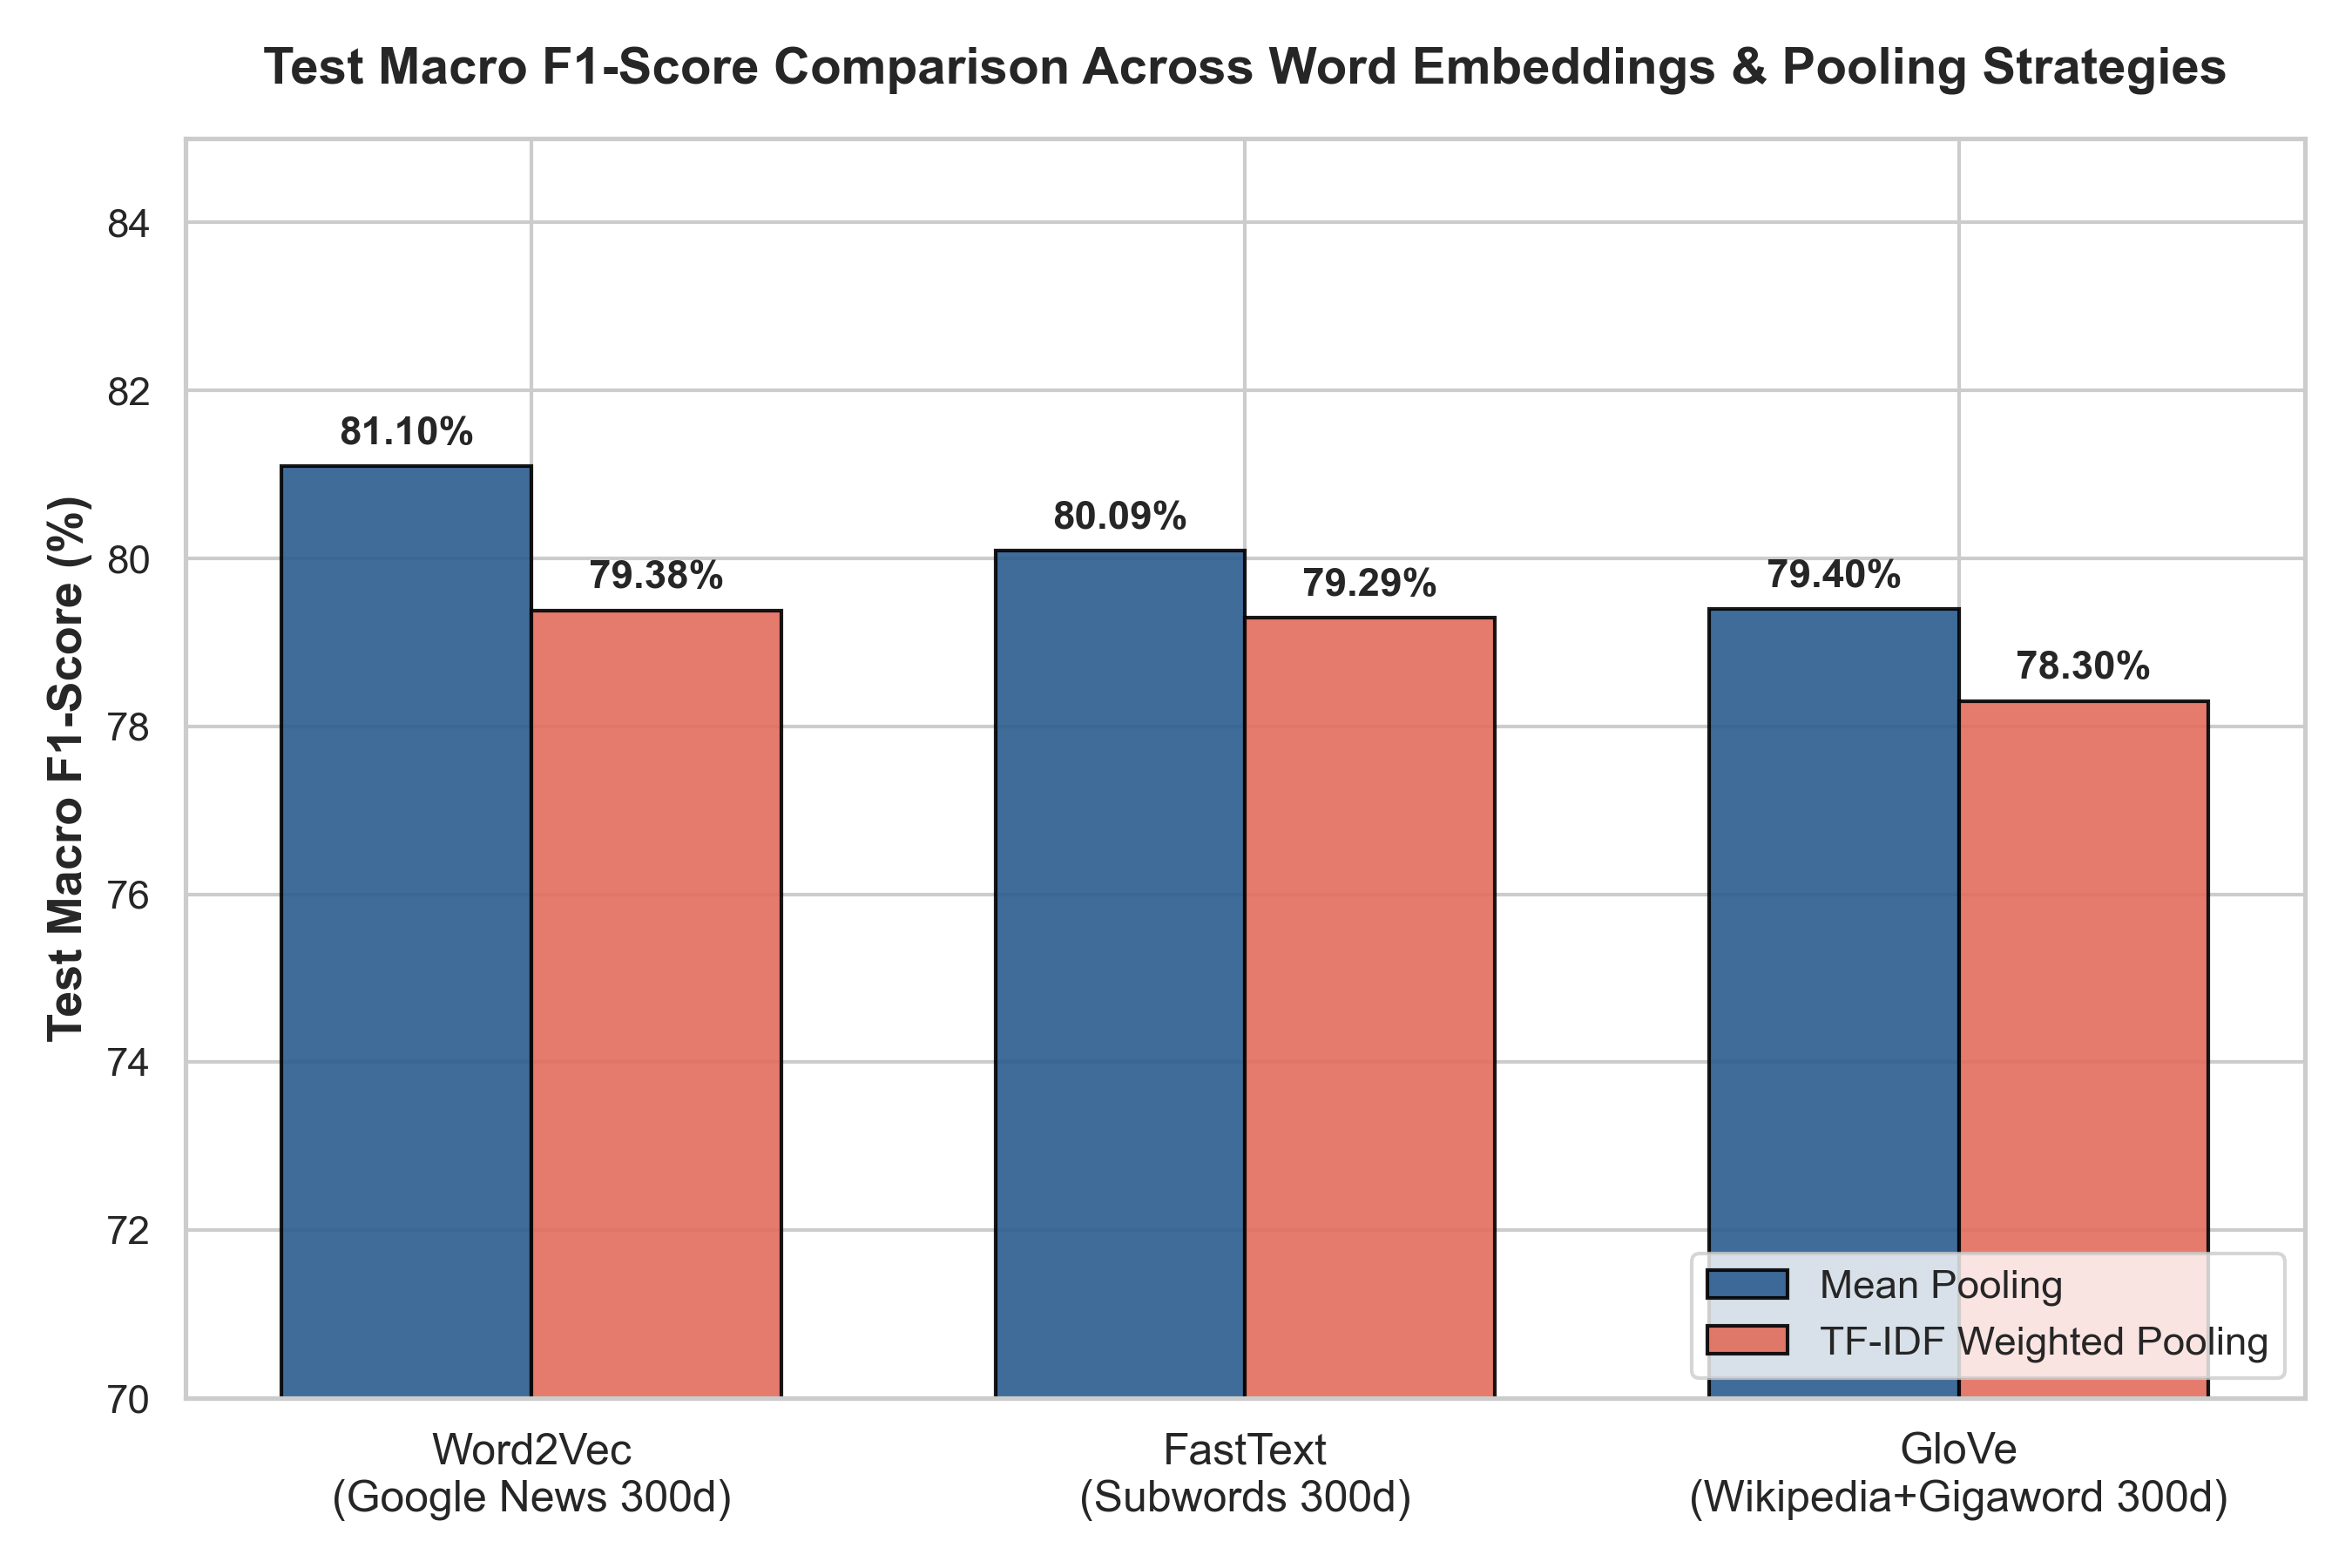


--- Plot 2: Google Analogy Benchmark Accuracy ---


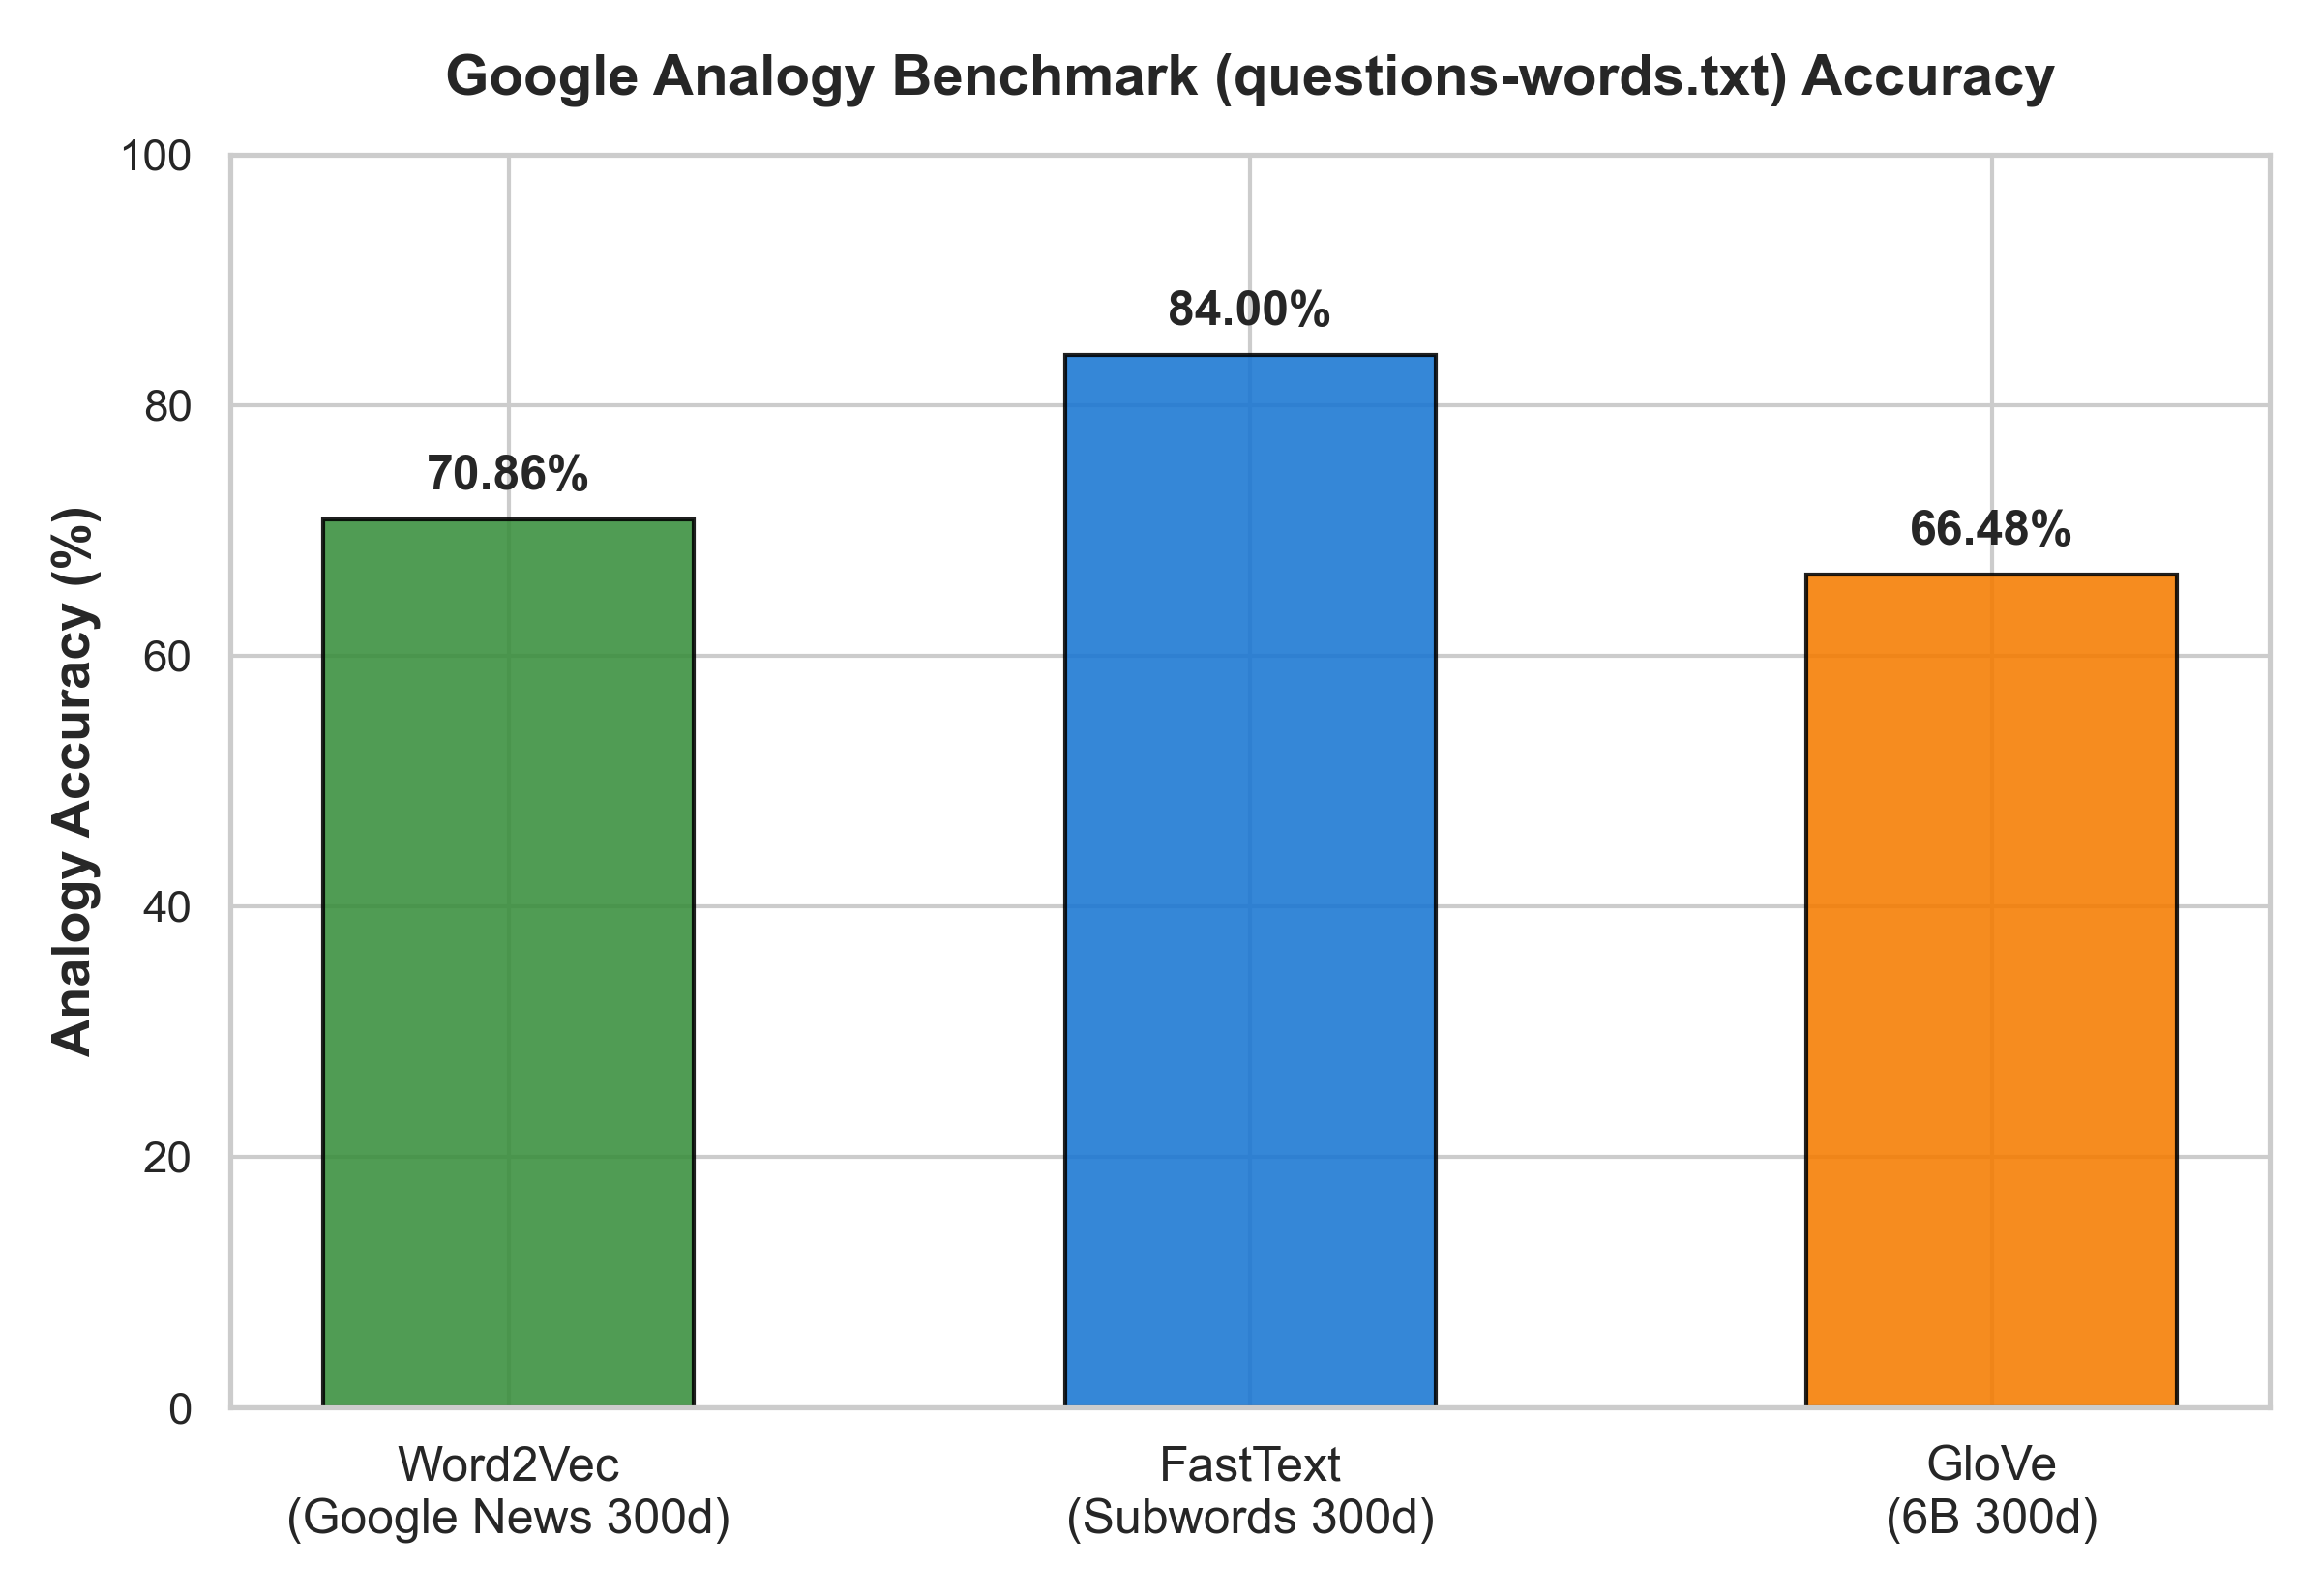


--- Plot 3: Neural Network Training Dynamics (Loss & Accuracy) ---


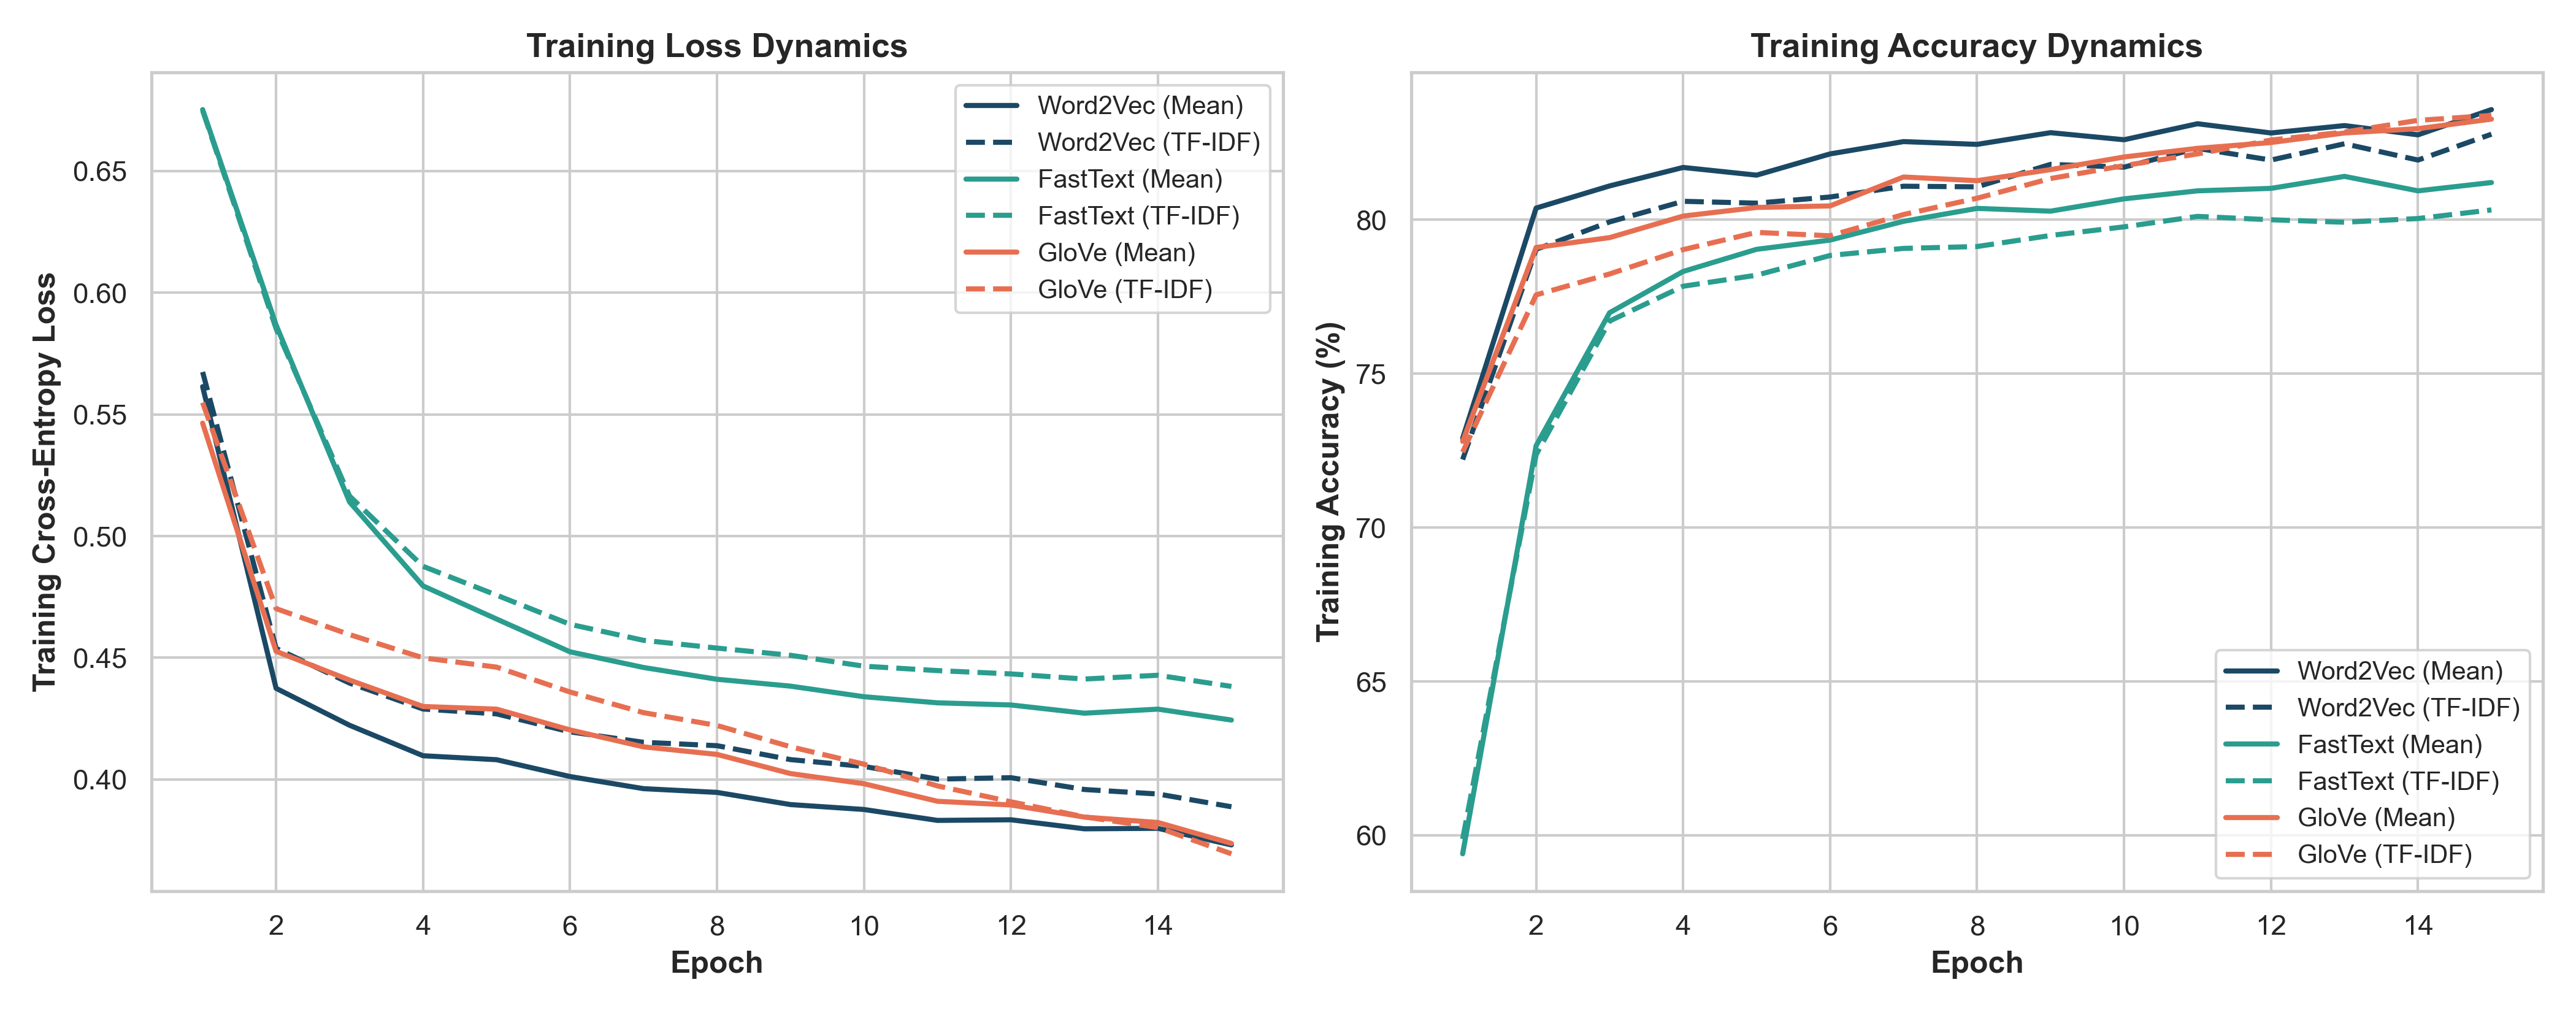


--- Plot 4: Confusion Matrices Across All Models ---


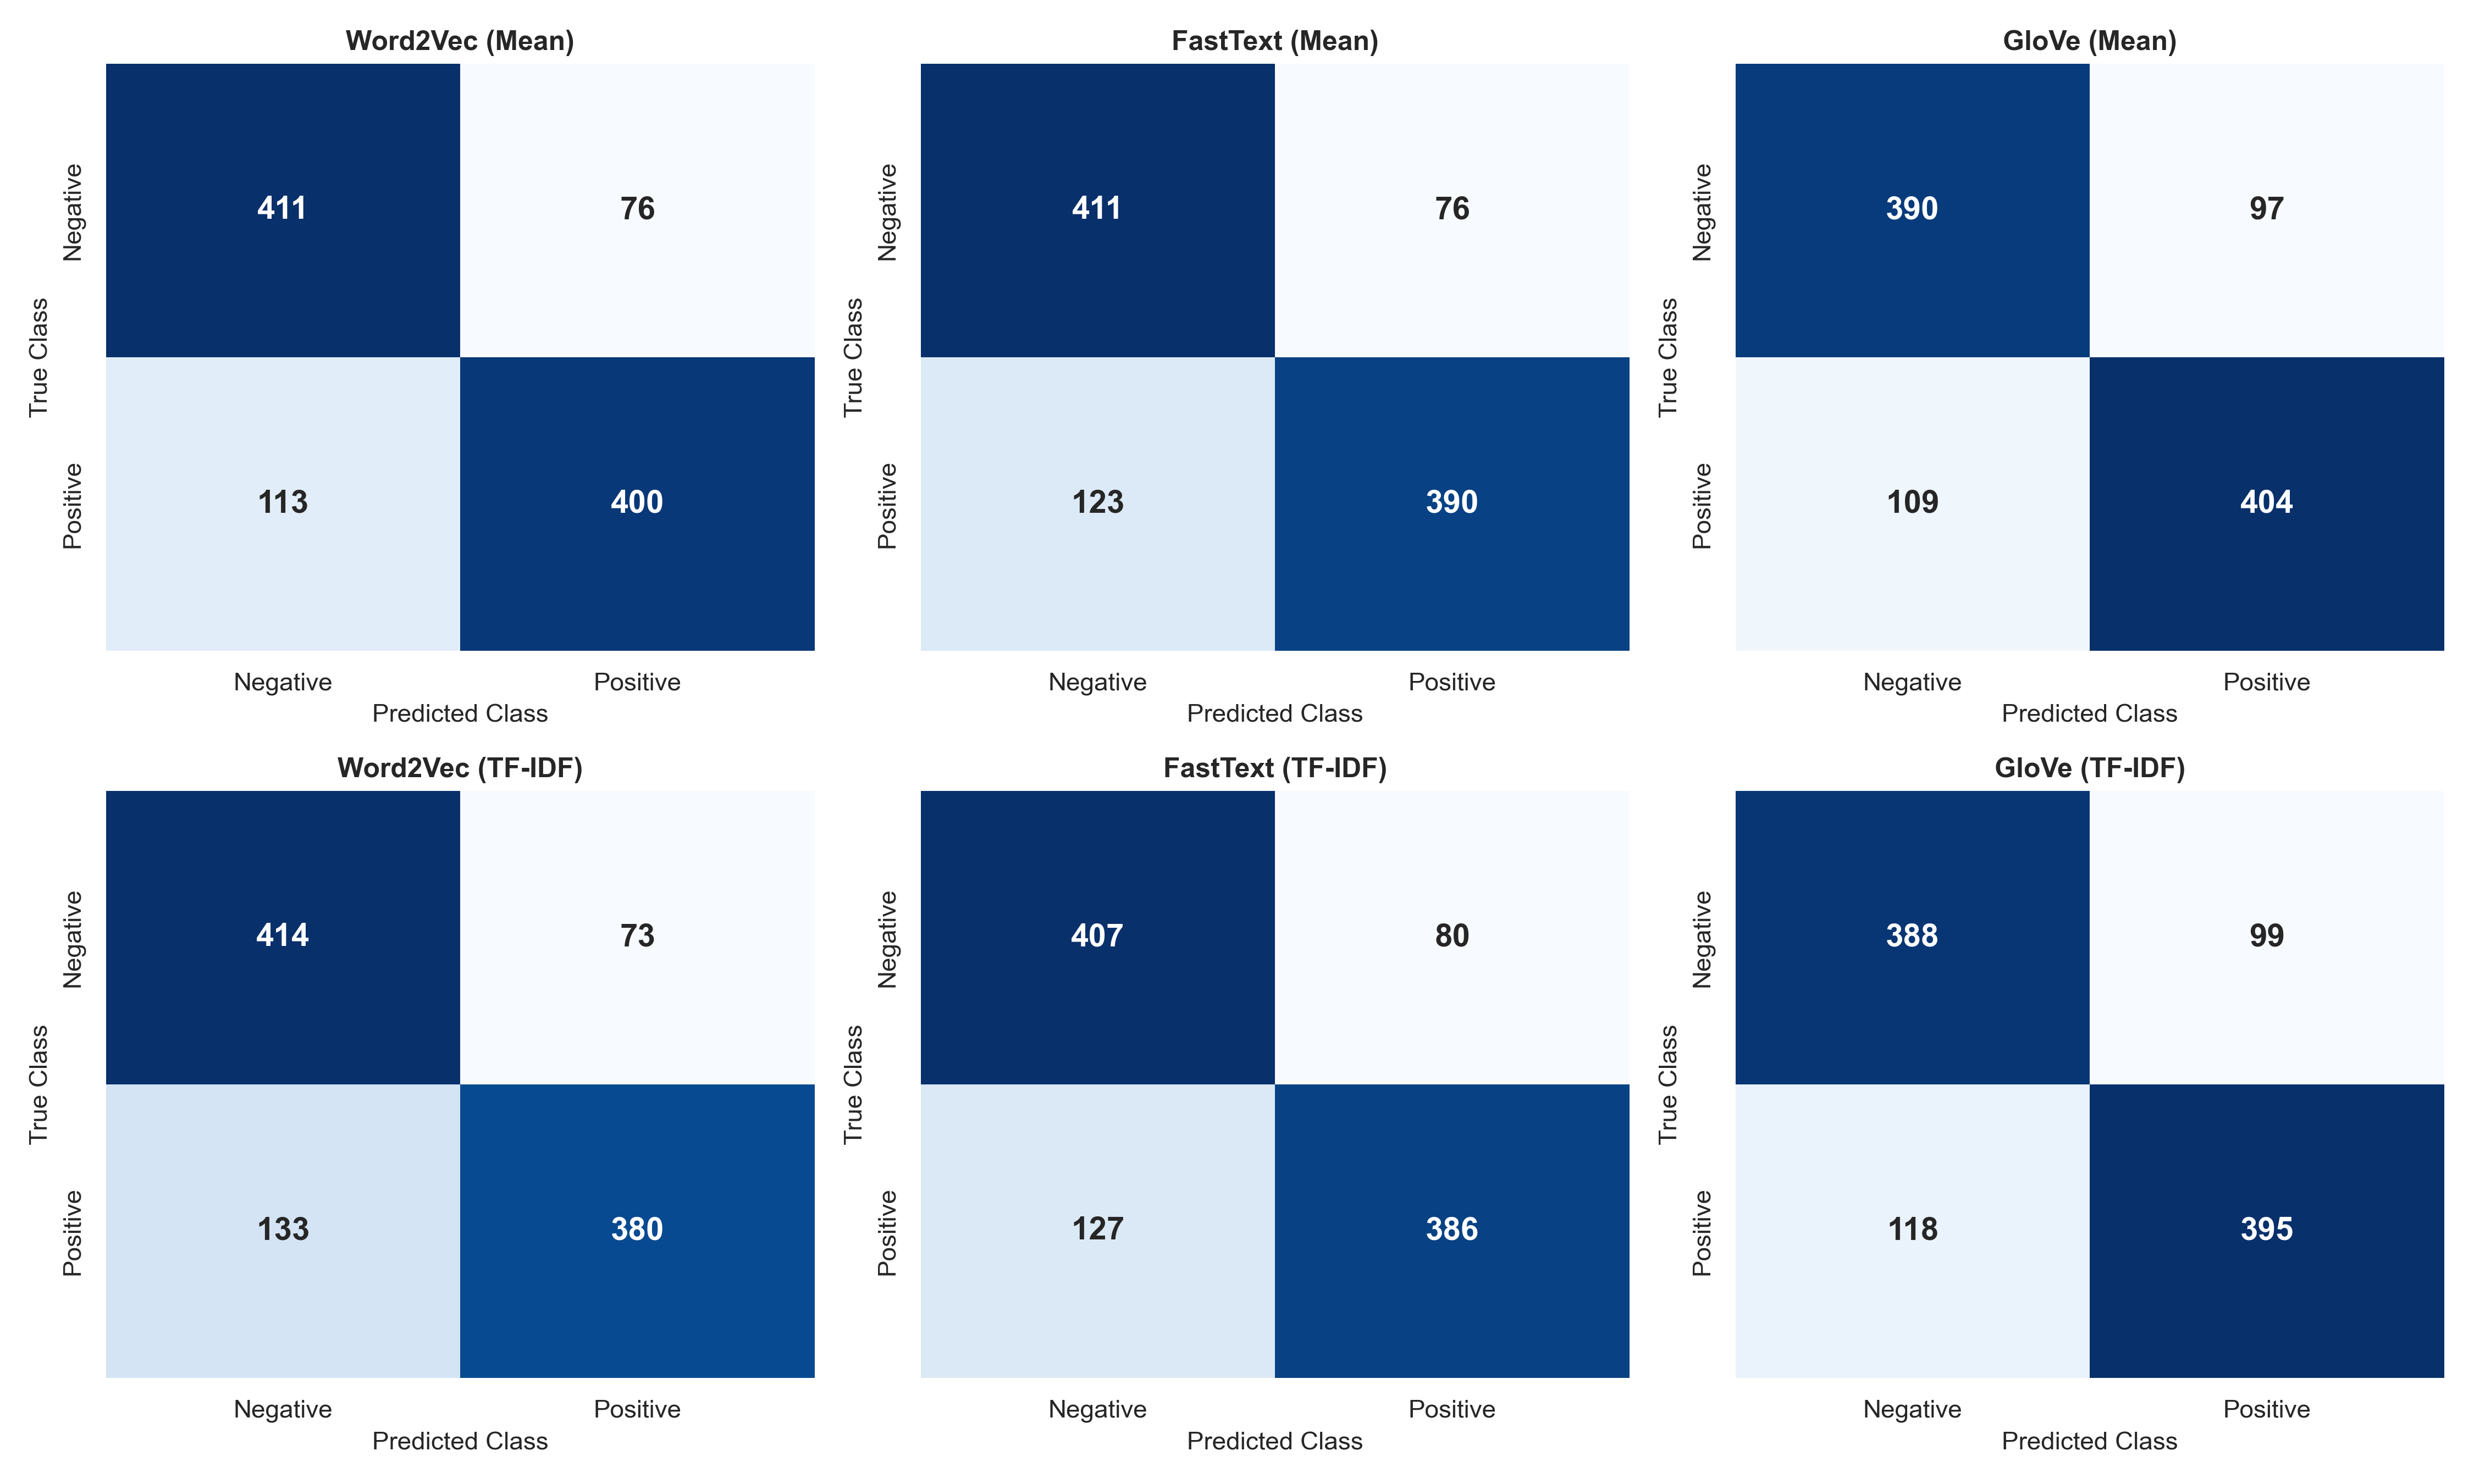

In [7]:
# =========================================================================
# 6. Publication-Quality Comparative Visualizations
# =========================================================================
from IPython.display import Image, display

print("--- Plot 1: Macro F1-Score Comparison Across Models & Pooling Strategies ---")
display(Image(filename="plots/macro_f1_comparison.png"))

print("\n--- Plot 2: Google Analogy Benchmark Accuracy ---")
display(Image(filename="plots/analogy_benchmark_comparison.png"))

print("\n--- Plot 3: Neural Network Training Dynamics (Loss & Accuracy) ---")
display(Image(filename="plots/training_curves.png"))

print("\n--- Plot 4: Confusion Matrices Across All Models ---")
display(Image(filename="plots/confusion_matrices.png"))


---
## 7. Comprehensive Discussion & Theoretical Insights

### 1. Word Analogy Performance & Subword Dynamics (Q2)
- **FastText's Dominance on Syntactic Analogies (84.00% overall):**
  FastText outperforms Word2Vec (70.86%) and GloVe (66.48%) by a substantial margin. This superiority is primarily driven by its **character $n$-gram subword embeddings** ($n \in [3, 6]$). In categories like `gram1-adjective-to-adverb` (`quick` $\to$ `quickly`, 70.7% vs 21.3% GloVe), `gram4-superlative` (`great` $\to$ `greatest`, 98.7% vs 73.3%), and `gram5-present-participle` (`sing` $\to$ `singing`, 96.7% vs 70.7%), morphological suffixes are encoded directly in the constituent $n$-grams.
- **Semantic Word Analogies:**
  For high-level semantic categories such as `capital-world` (GloVe 96.7%, FastText 94.7%, Word2Vec 80.0%) and `family` (GloVe 88.0%, Word2Vec 84.7%, FastText 84.0%), GloVe and FastText both demonstrate strong geometric alignment, while Word2Vec produces rich semantic synonyms (`good - bad + excellent` $\to$ `terrific`, `superb`, `fantastic`).

### 2. Sentence Representations: Mean Pooling vs TF-IDF Weighted Pooling (Q1 & Q3)
- In all three embedding architectures, **Mean Pooling consistently outperformed TF-IDF Weighted Pooling** by $+1.70\%$ (Word2Vec: $81.10\%$ vs $79.38\%$) and $+0.80\%$ (FastText: $80.09\%$ vs $79.29\%$).
- *Linguistic Explanation:* In Amazon sentiment reviews, evaluative sentiment is distributed across multiple clause constituents (e.g., adverbs, auxiliary verbs, common adjectives like "good", "great", "well"). Because TF-IDF heavily penalizes words with high document frequency, it suppresses frequent sentiment carriers in favor of rare product-specific nouns (e.g., specific camera or book names), introducing variance and attenuating sentiment signal.

### 3. Embedding Architecture Comparison for Downstream Classification (Q3)
- **Word2Vec (Google News 300d)** achieved the highest downstream Macro F1-score (**81.10%**), followed closely by **FastText** (**80.09%**) and **GloVe** (**79.40%**).
- Word2Vec's training on a colossal 100-billion-word Google News corpus with negative sampling yields tightly clustered semantic neighborhoods for sentiment adjectives and adverbs.
- FastText achieves near-identical classification performance ($80.09\%$) while guaranteeing zero Out-Of-Vocabulary failures through its subword architecture.
